# Activity 1: Multiple Linear Regression
**Unit I – Regression Foundations & Linear Regression | Marks: 5**

**Dataset:** California Housing Dataset (Scikit-learn)

**Objective:** Predict a continuous target using multiple numerical features, calculate a small two-feature model manually, verify it with a library, compare single-feature and multiple-feature models, interpret coefficients, diagnose residuals and multicollinearity, evaluate on unseen data, and predict one new example.

>

## Step 1 – Select and describe the dataset

The California Housing dataset contains census-block-group information from the 1990 California census.

- **Input features:** eight numerical variables: `MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, and `Longitude`.
- **Target:** `MedHouseVal`, the median house value in units of **$100,000**.
- **File type:** fetched dataset (original data distributed as a tabular dataset; loaded here into a pandas DataFrame).
- **Rows and columns:** displayed by the next cell.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# Load the dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
df = df.rename(columns={"MedHouseVal": "MedHouseVal"})

print("Dataset: California Housing")
print("Shape (rows, columns):", df.shape)
display(df.head())
print("\nDataset description:")
print(housing.DESCR[:1800])

Dataset: California Housing
Shape (rows, columns): (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Dataset description:
.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census

## Step 2 – Inspect and clean the data
Check data types, ranges, missing values and duplicate records. We will remove exact duplicate rows if any and drop rows with missing values if any. The next cell records whether any change was needed.

In [2]:
print("Data types:")
display(df.dtypes.to_frame("Data type"))

print("\nSummary statistics:")
display(df.describe().T)

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing count"))

print("\nDuplicate rows:", df.duplicated().sum())

rows_before = len(df)
df = df.drop_duplicates().dropna().copy()
print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Rows removed:", rows_before - len(df))

Data types:


,Data type
MedInc,float64
HouseAge,float64
AveRooms,float64
AveBedrms,float64
Population,float64
AveOccup,float64
Latitude,float64
Longitude,float64
MedHouseVal,float64



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010



Missing values:


,Missing count
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0



Duplicate rows: 0
Rows before cleaning: 20640
Rows after cleaning: 20640
Rows removed: 0


## Step 3 – Visualise relationships and correlations
Scatter plots show patterns between each feature and the target. Correlation describes linear association only; it does not establish causation.

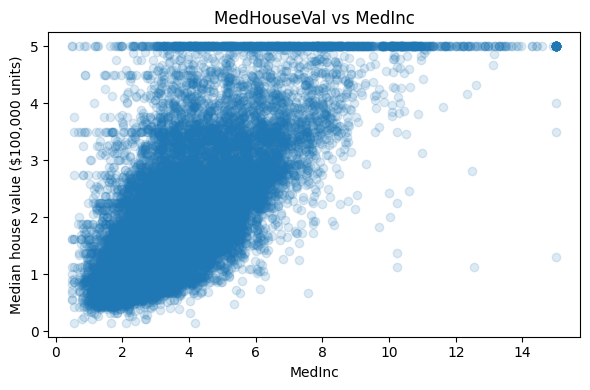

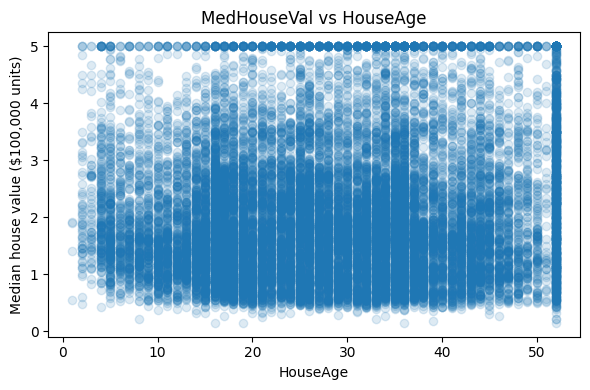

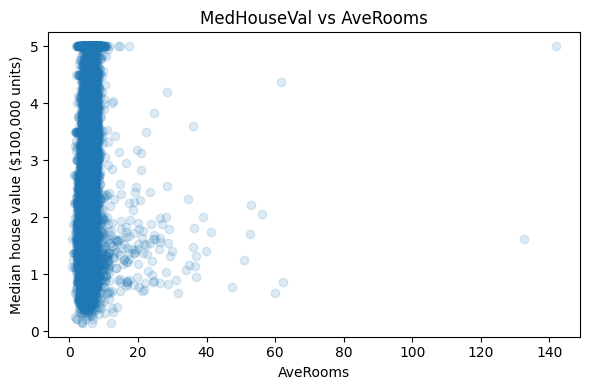

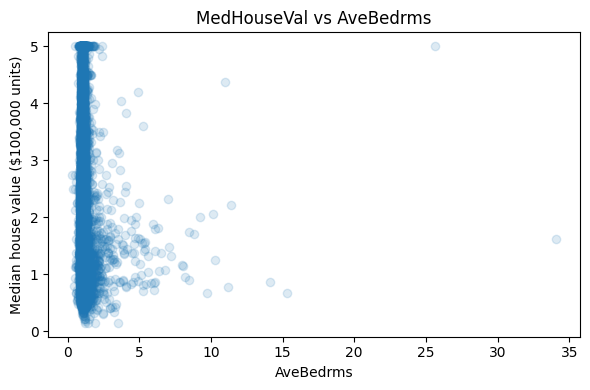

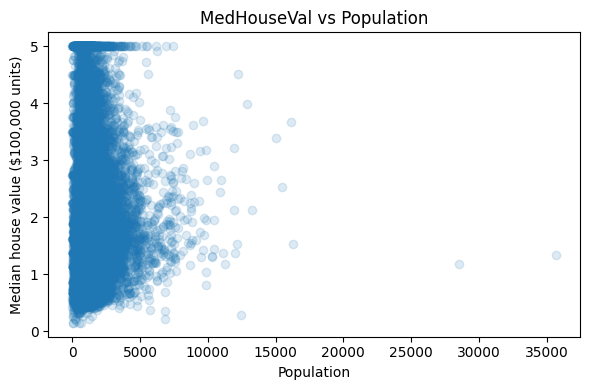

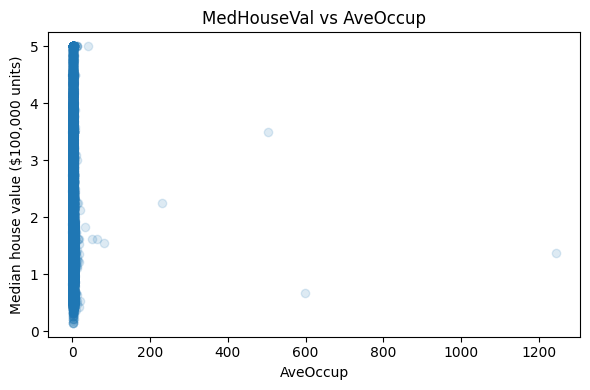

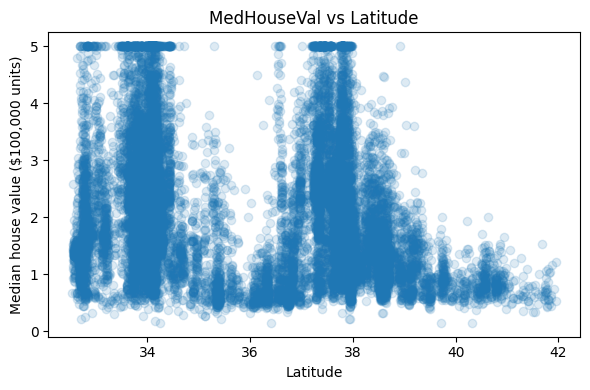

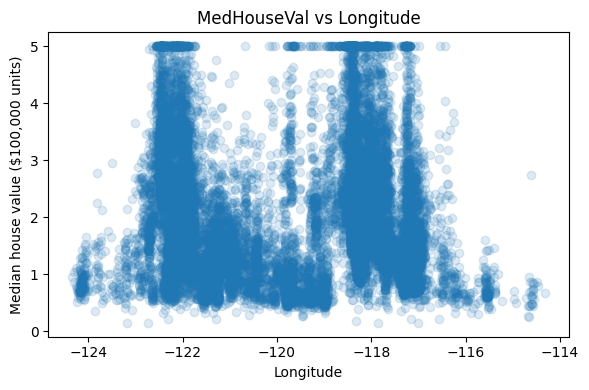

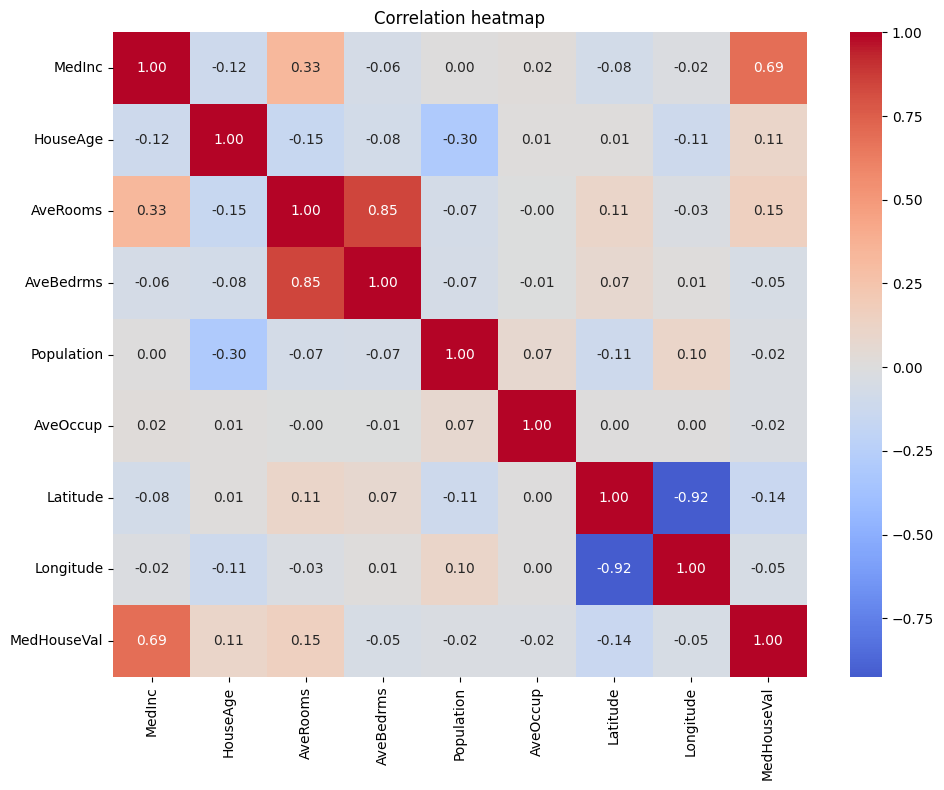

Feature-target correlations:


,Correlation with target
MedInc,0.688075
AveRooms,0.151948
Latitude,-0.144160
HouseAge,0.105623
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737



Feature-feature correlations (inspect large absolute values for possible multicollinearity):


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000


In [3]:
target = "MedHouseVal"
features = [c for c in df.columns if c != target]

for feature in features:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[feature], df[target], alpha=0.15)
    plt.xlabel(feature)
    plt.ylabel("Median house value ($100,000 units)")
    plt.title(f"{target} vs {feature}")
    plt.tight_layout()
    plt.show()

corr = df[features + [target]].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

print("Feature-target correlations:")
display(corr[target].drop(target).sort_values(key=abs, ascending=False).to_frame("Correlation with target"))
print("\nFeature-feature correlations (inspect large absolute values for possible multicollinearity):")
display(corr.loc[features, features])

## Step 4 – Manual calculation worksheet (two features, 5–8 records)

For the hand calculation, use two features: `MedInc` and `HouseAge`, and six observations selected reproducibly from the cleaned dataset.



In [4]:
manual_features = ["MedInc", "HouseAge"]
small = df.sample(n=6, random_state=42)[manual_features + [target]].reset_index(drop=True)

X_manual = np.column_stack([np.ones(len(small)), small[manual_features].to_numpy()])
y_manual = small[target].to_numpy().reshape(-1, 1)

XTX = X_manual.T @ X_manual
XTy = X_manual.T @ y_manual
b_manual = np.linalg.solve(XTX, XTy).ravel()

print("Six-observation sample:")
display(small)
print("Design matrix X (columns: 1, MedInc, HouseAge):")
print(X_manual)
print("\nTarget vector y:")
print(y_manual)
print("\nX transpose times X (XTX):")
print(XTX)
print("\nX transpose times y (XTy):")
print(XTy)
print("\nSolved coefficients [b0, b1, b2]:")
print(b_manual)
print(f"\nManual fitted equation: {target} = {b_manual[0]:.6f} + ({b_manual[1]:.6f} × MedInc) + ({b_manual[2]:.6f} × HouseAge)")

# Predict the first observation and calculate its residual
manual_prediction = X_manual[0] @ b_manual
manual_residual = y_manual[0, 0] - manual_prediction
print("\nFirst observation actual:", y_manual[0, 0])
print("First observation predicted:", manual_prediction)
print("Residual (actual - predicted):", manual_residual)

Six-observation sample:


,MedInc,HouseAge,MedHouseVal
0,1.6812,25.0,0.47700
1,2.5313,30.0,0.45800
2,3.4801,52.0,5.00001
3,5.7376,17.0,2.18600
4,3.7250,34.0,2.78000
5,4.7147,12.0,1.58700


Design matrix X (columns: 1, MedInc, HouseAge):
[[ 1.      1.6812 25.    ]
 [ 1.      2.5313 30.    ]
 [ 1.      3.4801 52.    ]
 [ 1.      5.7376 17.    ]
 [ 1.      3.725  34.    ]
 [ 1.      4.7147 12.    ]]

Target vector y:
[[0.477  ]
 [0.458  ]
 [5.00001]
 [2.186  ]
 [2.78   ]
 [1.587  ]]

X transpose times X (XTX):
[[   6.           21.8699      170.        ]
 [  21.8699       90.36908399  579.6998    ]
 [ 170.          579.6998     5818.        ]]

X transpose times y (XTy):
[[ 12.48801  ]
 [ 49.7419251]
 [436.39152  ]]

Solved coefficients [b0, b1, b2]:
[-4.21701573  0.82971144  0.11555528]

Manual fitted equation: MedHouseVal = -4.217016 + (0.829711 × MedInc) + (0.115555 × HouseAge)

First observation actual: 0.477
First observation predicted: 0.06677722419635135
Residual (actual - predicted): 0.41022277580364863


### Verify the hand calculation with a library
Fit `LinearRegression` on exactly the same six rows and two features. The coefficients should agree with the normal-equation solution apart from tiny floating-point differences.

In [5]:
manual_library = LinearRegression()
manual_library.fit(small[manual_features], small[target])

print("Manual coefficients:", b_manual)
print("Library intercept:", manual_library.intercept_)
print("Library coefficients:", manual_library.coef_)
print("Maximum absolute coefficient difference:",
      np.max(np.abs(b_manual - np.r_[manual_library.intercept_, manual_library.coef_])))

Manual coefficients: [-4.21701573  0.82971144  0.11555528]
Library intercept: -4.2170157345210395
Library coefficients: [0.82971144 0.11555528]
Maximum absolute coefficient difference: 7.105427357601002e-15


## Step 5 – Train/test split and fit models

Use an 80:20 split with a fixed random state so the results are reproducible. The single-feature baseline uses the feature with the strongest absolute correlation with the target **in the training set**. The multiple model uses all eight numerical input features. Both are evaluated on the same unseen test rows.

Ordinary least squares does not require scaling. We keep features in their original units so coefficient interpretation is direct.

In [6]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

train_corr = X_train.join(y_train).corr(numeric_only=True)[target].drop(target)
best_feature = train_corr.abs().idxmax()
print("Strongest training feature-target correlation:", best_feature, train_corr[best_feature])

single_model = LinearRegression()
single_model.fit(X_train[[best_feature]], y_train)

multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

print("\nSingle-feature model")
print("Intercept:", single_model.intercept_)
print("Coefficient:", single_model.coef_[0])

print("\nMultiple-feature model")
print("Intercept:", multiple_model.intercept_)
for name, coef in zip(features, multiple_model.coef_):
    print(f"{name}: {coef}")

Training observations: 16512
Testing observations: 4128
Strongest training feature-target correlation: MedInc 0.6906466061467654

Single-feature model
Intercept: 0.4445972916907879
Coefficient: 0.4193384939381271

Multiple-feature model
Intercept: -37.02327770606405
MedInc: 0.4486749096657175
HouseAge: 0.009724257517905038
AveRooms: -0.12332334282795937
AveBedrms: 0.7831449067929716
Population: -2.0296205801330347e-06
AveOccup: -0.003526318487134326
Latitude: -0.4197924865883591
Longitude: -0.4337080649639867


## Step 6 – Interpret the multiple regression equation

The next cell prints the fitted equation using the actual training-set coefficients.

Interpretation rule: a coefficient is the predicted change in `MedHouseVal` for a one-unit increase in that feature, **holding all other included features constant**. Since the target is measured in $100,000 units, multiply a predicted target change by 100,000 to express it in dollars.

The intercept is the model prediction when all features equal zero. That combination may not represent a realistic California area, so the intercept may have limited practical meaning. Raw coefficient magnitudes cannot be compared directly when features use different units.

In [8]:
equation = f"{target} = {multiple_model.intercept_:.6f}"
for name, coef in zip(features, multiple_model.coef_):
    equation += f" + ({coef:.6f} × {name})"
print("Fitted multiple regression equation:")
print(equation)


# Standardised coefficients for a rough relative comparison
X_train_std = (X_train - X_train.mean()) / X_train.std(ddof=0)
y_train_std = (y_train - y_train.mean()) / y_train.std(ddof=0)
standardised_model = LinearRegression().fit(X_train_std, y_train_std)
standardised_coefs = pd.Series(standardised_model.coef_, index=features)
print("\nStandardised coefficients (rough relative influence; not causation):")
display(standardised_coefs.sort_values(key=abs, ascending=False).to_frame("Standardised coefficient"))

Fitted multiple regression equation:
MedHouseVal = -37.023278 + (0.448675 × MedInc) + (0.009724 × HouseAge) + (-0.123323 × AveRooms) + (0.783145 × AveBedrms) + (-0.000002 × Population) + (-0.003526 × AveOccup) + (-0.419792 × Latitude) + (-0.433708 × Longitude)

Standardised coefficients (rough relative influence; not causation):


,Standardised coefficient
Latitude,-0.775762
Longitude,-0.752334
MedInc,0.738963
AveBedrms,0.293429
AveRooms,-0.254638
HouseAge,0.105991
AveOccup,-0.035313
Population,-0.001996


## Step 7 – Generate and compare test predictions
Show actual and predicted values for a small sample of test observations. These are test predictions, not training predictions.

In [9]:
pred_single = single_model.predict(X_test[[best_feature]])
pred_multiple = multiple_model.predict(X_test)

prediction_table = pd.DataFrame({
    "Actual MedHouseVal": y_test,
    "Single-feature prediction": pred_single,
    "Multiple-feature prediction": pred_multiple
}).head(10)
display(prediction_table)

,Actual MedHouseVal,Single-feature prediction,Multiple-feature prediction
20046,0.47700,1.149589,0.719123
3024,0.45800,1.506069,1.764017
15663,5.00001,1.903937,2.709659
20484,2.18600,2.850594,2.838926
9814,2.78000,2.006633,2.604657
13311,1.58700,2.421652,2.011754
7113,1.98200,2.576472,2.645500
7668,1.57500,1.992292,2.168755
18246,3.40000,2.458932,2.740746
5723,4.46600,3.846774,3.915615


## Step 8 – Evaluate the models on the test set

- **MAE:** average absolute prediction error.
- **MSE:** average squared prediction error.
- **RMSE:** square root of MSE; it is in the target's units.
- **R²:** compares the model with predicting the test-set mean; it can be negative on test data.
- **Adjusted R²:** penalises the use of additional features that contribute little.

Adjusted R² below is calculated from test R², test sample size and number of predictors, as requested for a test-set comparison.

In [10]:
def regression_metrics(y_true, y_pred, p):
    n = len(y_true)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1) if n > p + 1 else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "Adjusted R2": adjusted_r2}

single_metrics = regression_metrics(y_test, pred_single, p=1)
multiple_metrics = regression_metrics(y_test, pred_multiple, p=len(features))

comparison = pd.DataFrame(
    [single_metrics, multiple_metrics],
    index=[f"Single feature ({best_feature})", "Multiple features"]
)
display(comparison)

print("Decision guide:")
print("- Lower MAE, MSE and RMSE are better.")
print("- Higher test R2 and adjusted R2 are better.")
print("- Decide whether the extra features justify their complexity using these test results.")

,MAE,MSE,RMSE,R2,Adjusted R2
Single feature (MedInc),0.629909,0.709116,0.842090,0.458859,0.458728
Multiple features,0.533200,0.555892,0.745581,0.575788,0.574964


Decision guide:
- Lower MAE, MSE and RMSE are better.
- Higher test R2 and adjusted R2 are better.
- Decide whether the extra features justify their complexity using these test results.


## Step 9 – Residual analysis and regression assumptions
Residual = actual value − predicted value. A good residual plot should show a roughly random cloud around zero, without a clear curve or funnel shape.

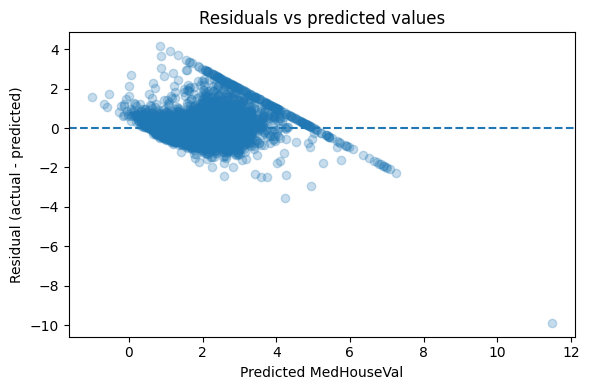

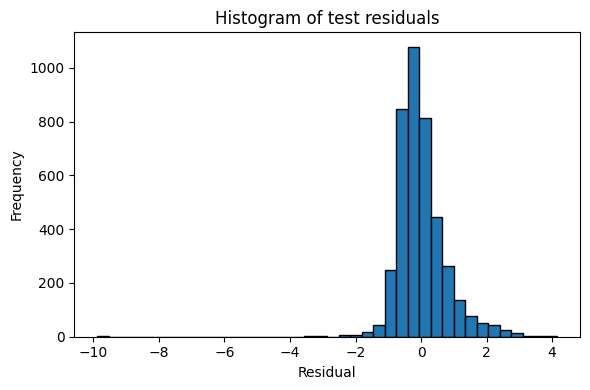

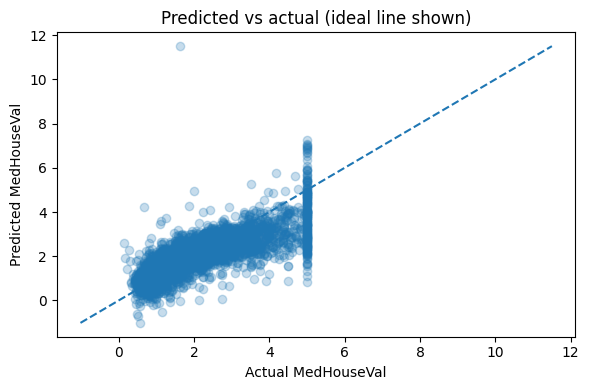

Residual mean: 0.0034792979037524545
Residual standard deviation: 0.74566358804791


In [12]:
residuals = y_test - pred_multiple

plt.figure(figsize=(6, 4))
plt.scatter(pred_multiple, residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted MedHouseVal")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals vs predicted values")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=40, edgecolor="black")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Histogram of test residuals")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(y_test, pred_multiple, alpha=0.25)
limits = [min(y_test.min(), pred_multiple.min()), max(y_test.max(), pred_multiple.max())]
plt.plot(limits, limits, linestyle="--")
plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.title("Predicted vs actual (ideal line shown)")
plt.tight_layout()
plt.show()

print("Residual mean:", residuals.mean())
print("Residual standard deviation:", residuals.std())

### Multicollinearity check using correlation and VIF
VIF is calculated using the training features. A high VIF (commonly above 5, and especially above 10) can indicate problematic multicollinearity; thresholds are guidelines, not absolute rules.

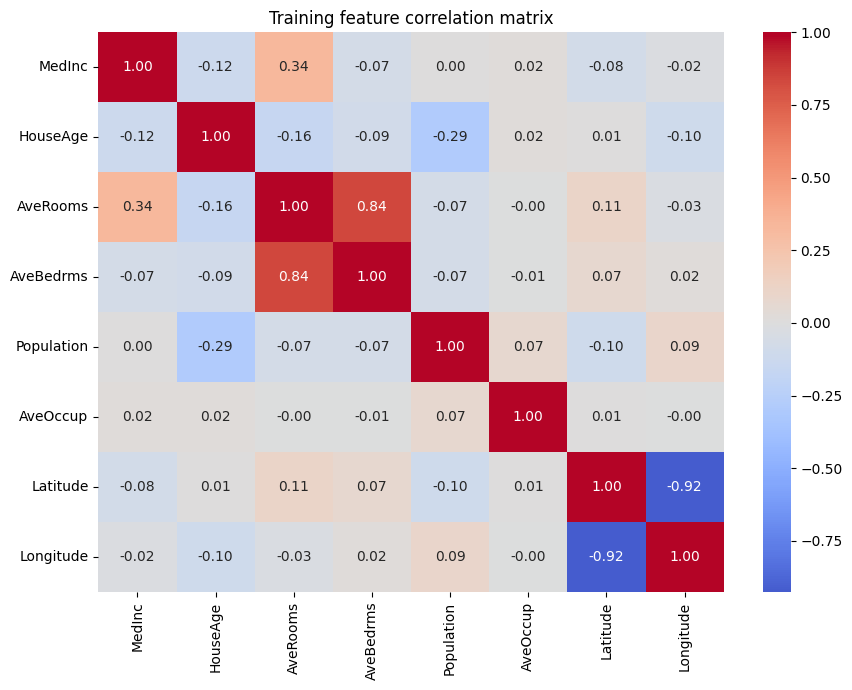

,Feature,VIF
6,Latitude,9.206134
7,Longitude,8.875984
2,AveRooms,7.917240
3,AveBedrms,6.609200
0,MedInc,2.539815
1,HouseAge,1.237337
4,Population,1.134824
5,AveOccup,1.009733


In [13]:
feature_corr = X_train.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(feature_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Training feature correlation matrix")
plt.tight_layout()
plt.show()

X_vif = sm.add_constant(X_train)
vif_table = pd.DataFrame({
    "Feature": X_train.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(features))]
}).sort_values("VIF", ascending=False)
display(vif_table)

## Step 10 – Predict one new example and conclude

Use feature values within the training data ranges where possible. The example below uses the median of each training feature, which is a reasonable in-range example. The prediction is in units of $100,000; multiply by 100,000 to convert to dollars.

This is an association-based prediction, not a guaranteed sale price or causal estimate.

In [14]:
new_house = X_train.median().to_frame().T
new_prediction = multiple_model.predict(new_house)[0]

print("New example feature values:")
display(new_house)
print(f"Predicted median house value: {new_prediction:.4f} × $100,000")
print(f"Approximate predicted value: ${new_prediction * 100000:,.2f}")

New example feature values:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,3.5458,29.0,5.235874,1.049286,1167.0,2.81724,34.26,-118.51


Predicted median house value: 2.0300 × $100,000
Approximate predicted value: $203,002.36


### Conclusion template

In this activity, I implemented Multiple Linear Regression using the California Housing Dataset to predict median house values based on multiple input features. I performed data preprocessing, visualisation, manual matrix calculations and model training using Python. I compared Single Linear Regression with Multiple Linear Regression using MAE, MSE, RMSE, R² and Adjusted R². I also analysed residuals and checked multicollinearity using correlation and VIF. Finally, I predicted a new house value using the trained model. This activity helped me understand how multiple features influence predictions and how to evaluate regression model performance. I learned that adding more features does not always improve accuracy and that proper model evaluation is important for making reliable predictions.